# 04: Modelos RNN y LSTM para Predicción de Casos

Este segundo modelo tiene como objetivo predecir la cantidad de caso que habrá dentro de cuatro semanas después de escoger una semana en particular, esto por medio de un modelo RNN y LSTM.

# 1. Carga de Librerías

In [64]:
#Librerías para leer, manejar datos, y generar gráficos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf #Lib para construir y entrenar redes.

#Herramientas adicionales
from sklearn.metrics import mean_absolute_error, mean_squared_error
from math import sqrt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.layers import LSTM, Dense, Dropout

## 1.1 Carga de Datos

In [65]:
modelo2 = pd.read_csv(
    "../data/processed/modelo2_preprocesado.csv"
)

Como en el CSV del modelo la columna "target" quedó escalada entonces se procederá a traer el archivo "crudo" para que el baseline lo pueda trabajar

In [66]:
dengue = pd.read_csv(
    "../data/processed/vectoria_dengue_semanal.csv"
)

# CAMBIAR A: "../data/raw/RNN/vectoria_dengue_semanal.csv" CUANDO YA LO ENTRENÉ

## 1.3 Orden Temporal

In [67]:
dengue["fecha_inicio_semana"] = pd.to_datetime(
    dengue["fecha_inicio_semana"] #La fecha viene como texto y se convierte a tipo date.
)

#Se ordena de la fecha más antigua a la más reciente.
dengue = dengue.sort_values(
    "fecha_inicio_semana"
)


# 2 Predicción Estacional

In [68]:
dengue["baseline_pred"] = (
    dengue["casos_dengue"]
    .shift(52) #Desplaza la columna 52 posiciones hacia abajo.
)

## 2.1 Eliminación de Filas no útiles

In [69]:
#Se descartan las filas donde baseline_pred está vacío, pues no se puede evaluar una predicción que no existe.
baseline = dengue.dropna(
    subset=["baseline_pred"]
).copy() #crea una copia independiente para no modificar el DataFrame original.

# 3. Métricas

In [71]:
mae_baseline = mean_absolute_error( #promedio de las diferencias en valor absoluto.
    baseline["casos_dengue"],
    baseline["baseline_pred"]
)

rmse_baseline = sqrt( #eleva los errores al cuadrado, los promedia y saca la raíz.
    mean_squared_error(
        baseline["casos_dengue"],
        baseline["baseline_pred"]
    )
)

#Para imprimir los resultados
print(
    f"Baseline MAE : {mae_baseline:.2f}"
)

print(
    f"Baseline RMSE: {rmse_baseline:.2f}"
)

Baseline MAE : 26.33
Baseline RMSE: 41.34


## 3.1 Visualización 

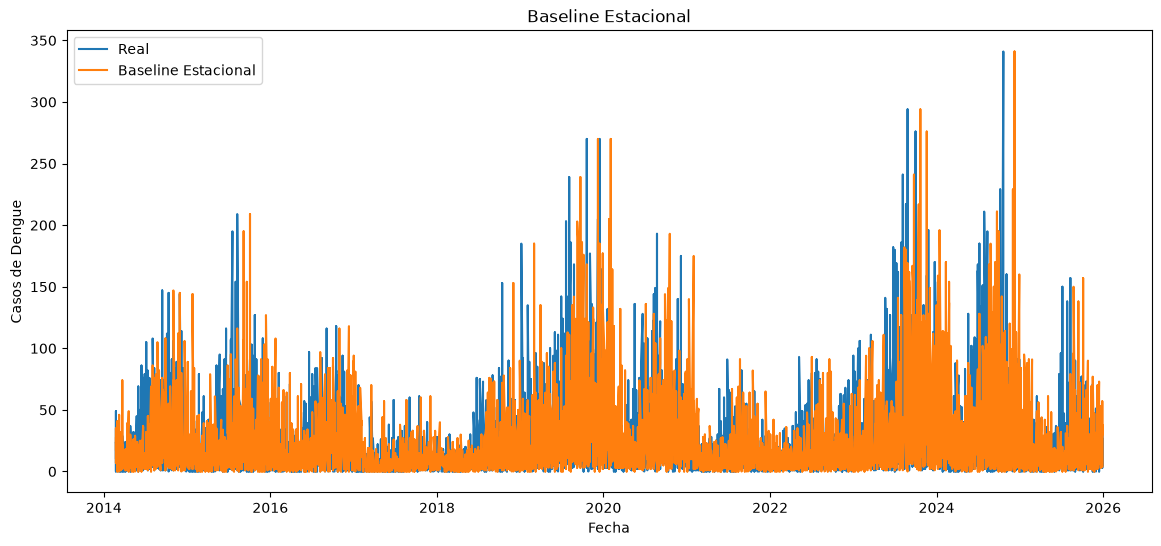

In [72]:
#Grafica en la misma figura los casos reales y la predicción del baseline a lo largo del tiempo.
plt.figure(figsize=(14,6))

plt.plot(
    baseline["fecha_inicio_semana"],
    baseline["casos_dengue"],
    label="Real"
)

plt.plot(
    baseline["fecha_inicio_semana"],
    baseline["baseline_pred"],
    label="Baseline Estacional"
)

plt.legend()

plt.title(
    "Baseline Estacional"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Casos de Dengue"
)

plt.show()

El gráfico es la representación visual de lo que se obtuvo en:
- Baseline MAE : 26.33
- Baseline RMSE: 41.34

Lo cual nos dice que en promedio el baseline se equivoca en aproximadamente 26 casos por semana y en semanas epidémicas aumenta aún mas esta penalización.

Ahora con esto ya sabido se busca que el modelo RNN de menores resultados que este y el LSTM sea menor al RNN

# 4. RNN

Ahora si se procederá con la creación del modelo RNN y como mencionamos anteriormente nuestro objetivo es conseguir menores métricas que el baseline

## 4.1 Obtención de X y Y

In [73]:
#Variables de entrada.
X = modelo2.drop(
    columns=[
        "fecha_inicio_semana",
        "target"
    ]
).values

#Variables de salida (Lo que se quiere predecir).
y = modelo2["target"].values

print(X.shape)

print(y.shape)

(4374, 25)
(4374,)


En este caso no vamos a utilizar "fecha_inicio_semana" como valor de entrada

## 4.2 Creación de Variables Temporales

In [74]:
WINDOW_SIZE = 26 #Se encarga de que el ciclo recorra la tabla y, en cada posición i.

X_seq = []
y_seq = []

for i in range(
    WINDOW_SIZE,
    len(X)
):

    X_seq.append(
        X[
            i-WINDOW_SIZE:i
        ]
    )

    y_seq.append(
        y[i]
    )

X_seq = np.array(X_seq)

y_seq = np.array(y_seq)

print(X_seq.shape)
print(y_seq.shape)

(4348, 26, 25)
(4348,)


En este caso utilizaremos 12 semanas del historial para crear cuatro semanas próximas

## 4.3 División Temporal

In [75]:
#Aquí los datos se dividen en tres bloques consecutivos en el tiempo.
train_size = int(
    len(X_seq) * 0.70
)

val_size = int(
    len(X_seq) * 0.15
)

#Entrenamiento
X_train = X_seq[:train_size]

y_train = y_seq[:train_size]

# Validación
X_val = X_seq[
    train_size:
    train_size + val_size
]

y_val = y_seq[
    train_size:
    train_size + val_size
]

#Test
X_test = X_seq[
    train_size + val_size:
]

y_test = y_seq[
    train_size + val_size:
]

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(3043, 26, 25)
(652, 26, 25)
(653, 26, 25)


Se realiza la división de las semanas en:

- Entrenamiento
- Validación 
- Prueba

Normalmente se dividen los datos solamente en entrenamiento y prueba, pero se agregó también validación para que esta pueda monitorear el entrenamiento y "EarlyStopping()" funcione de manera correcta, además de que el modelo no aprende de estos datos.

Algo que hay que tomar en cuenta es que la división no puede ser aleatoria, se debe de respetar el tiempo para tener una mejor predicción.

# 5. Creación de la RNN

In [76]:
model_rnn = Sequential([

    SimpleRNN( #Capa recurrente

        64,

        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )

    ),

    Dropout( #durante el entrenamiento apaga al azar el 20 % de las neuronas en cada paso.
        0.20
    ),

    Dense( #Capa normal de 32 neuronas.
        32,
        activation="relu" #ReLU deja pasar los valores positivos y convierte los negativos en 0, esto permite aprender relaciones no lineales.
    ),

    Dense( #La salida.
        1
    )

])

/home/sebas/Vector_IA/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


En el código se genera un diccionario de mapeo que permite ver el número asginado a cada categoría, esto permite interpretar los resultados de manera mas sencilla.

## 5.1 Summary

In [77]:
model_rnn.compile(

    optimizer="adam", #el algoritmo que ajusta los pesos de la red.

    loss="mse", #la función de error que la red intenta minimizar.

    metrics=["mae"] #métrica adicional para que se muestre en cada época (No influye en el aprendizaje, solo es informativa).

)

model_rnn.summary() #Tabla con las capas, la forma de la salida de cada una y la cantidad de parámetros que se entrenarán.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,873 (30.75 KB)

 Trainable params: 7,873 (30.75 KB)

 Non-trainable params: 0 (0.00 B)

Este nos mustra un resumen de como está compuesto el modelo.

## 5.2 Callbacks

In [78]:
callbacks = [

    EarlyStopping( #Observa el error en validación

        monitor="val_loss",

        patience=10,

        restore_best_weights=True

    ),

    ReduceLROnPlateau( #Si el error de validación no mejora durante 5 épocas, reduce a la mitad la tasa de aprendizaje.

        monitor="val_loss",

        factor=0.5,

        patience=5

    )
#Al ambos usar "val_loss" es necesario que haya un conjunto de validación.
]

Recordatorio que los callbacks es la retroalimentación que genera el código durante el entrenamiento para monitorear y optimizar en tiempo real mientras este se está ejecutando (razón por la que se utilizó "val").

# 6. Entrenamiento

In [79]:
history_rnn = model_rnn.fit( #Guarda el error y las métricas de cada época, útil para graficar la curva de aprendizaje.

#Datos con los que la red aprende.
    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=50, #Máximo de pasadas completas sobre el entrenamiento

    batch_size=32, #Para que la red vea 32 ventanas a la vez y ajuste sus pesos después de cada lote.

    callbacks=callbacks

)

Epoch 1/50


I0000 00:00:1793897370.329747   17115 dot_merger.cc:481] Merging Dots in computation: sequential_3_1_simple_rnn_2_1_while_body_61440_grad_61684_const_0__.19.clone.clone.clone.clone.clone
I0000 00:00:1793897370.329926   17115 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_62153__.20


94/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0271 - mae: 0.1127

I0000 00:00:1793897372.216685   17118 dot_merger.cc:481] Merging Dots in computation: sequential_3_1_simple_rnn_2_1_while_body_61440_grad_61684_const_0__.19.clone.clone.clone.clone.clone
I0000 00:00:1793897372.216789   17118 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_62153__.20


96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.0269 - mae: 0.1121 - val_loss: 0.0182 - val_mae: 0.0850 - learning_rate: 0.0010
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0091 - mae: 0.0666 - val_loss: 0.0161 - val_mae: 0.0794 - learning_rate: 0.0010
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0077 - mae: 0.0602 - val_loss: 0.0164 - val_mae: 0.0794 - learning_rate: 0.0010
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0071 - mae: 0.0570 - val_loss: 0.0149 - val_mae: 0.0784 - learning_rate: 0.0010
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0068 - mae: 0.0560 - val_loss: 0.0148 - val_mae: 0.0774 - learning_rate: 0.0010
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0065 - mae: 0.0546 - val_loss: 0.0141 - val_mae: 0.0772 - learning_rate: 0.0010
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0063 - mae: 0.0529 - val_loss: 0.0139 - val_mae: 0.0762 - learning_rate: 0.0010
Epoch 8/50
96/96 ━━━━━━━━

## 6.1 Predicciones

In [80]:
pred_rnn = model_rnn.predict(
    X_test
)
#Aquí se le dan al modelo las ventanas del test, que nunca vio, y devuelve sus predicciones.

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


## 6.2 Reconstruir Target Original

Para una comparativa de manera directa entre el Baseline y el RNN necesitamos obtener el target con sus valores reales y no escalado, por lo cual se va a realizar de manera rápida este apartado

In [81]:
dengue = dengue.sort_values(
    "fecha_inicio_semana"
)

dengue["target"] = (
    dengue["casos_dengue"]
    .shift(-4) #Toma el valor de 4 filas hacia delante
)

dengue = dengue.dropna() #Para eliminanr las filas finales que quedan vacías porque no tienen un valor 4 semanas más adelante.

Recordemos que ya se había llamado para el baseline

## 6.3 Obtención del Mínimo, Máximo y Promedio

In [99]:
target_min = dengue["target"].min()

target_max = dengue["target"].max()


print("Min:", target_min)
print("Max:", target_max)


Min: 0.0
Max: 341.0


El MinMaxScaler transformó cada valor con la fórmula (x - min) / (max - min). Para deshacerlo se necesitan los mismos min y max originales, y de aquí se obtienen.

## 6.4 Función de Desescalamiento

In [83]:
def inverse_minmax(
    values,
    min_val,
    max_val
):

    return values * (
        max_val - min_val
    ) + min_val

Es la fórmula inversa. Si una predicción es 0.5, el valor real es 0.5 * (max - min) + min, es decir, el punto medio del rango.

## 6.5 Desescalar la RNN

In [84]:
#Aquí se convierten a casos reales tanto los valores verdaderos del test como las predicciones.
y_test_real = inverse_minmax(
    y_test,
    target_min,
    target_max
)

pred_rnn_real = inverse_minmax(
    pred_rnn.flatten(), #Convierte la salida del modelo, que viene como columna, en un vector simple.
    target_min,
    target_max
)

Ya el modelo está creado y la variable target está desescalada, ahora se procede a mostrar el RSME y MAE real.

## 6.6 RMSE

In [85]:
#Aquí se calculan MAE y RMSE exactamente igual que en el baseline, pero con y_test_real y pred_rnn_real.
mae_rnn_real = mean_absolute_error(
    y_test_real,
    pred_rnn_real
)

rmse_rnn_real = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_rnn_real
    )
)

print(
    f"RNN MAE Real : {mae_rnn_real:.2f}"
)

print(
    f"RNN RMSE Real: {rmse_rnn_real:.2f}"
)

RNN MAE Real : 23.52
RNN RMSE Real: 34.94


## 6.7 Comparación con Baseline

In [86]:
#Imprime las métricas del baseline junto a las de la RNN.
print(
    f"Baseline MAE  : 26.15"
)

print(
    f"Baseline RMSE : 41.15"
)

print(
    f"\nRNN MAE Real  : {mae_rnn_real:.2f}"
)

print(
    f"RNN RMSE Real : {rmse_rnn_real:.2f}"
)


Baseline MAE  : 26.15
Baseline RMSE : 41.15

RNN MAE Real  : 23.52
RNN RMSE Real : 34.94


Observamos que posee una disminución con respecto al baseline pero aún así esta diferencia no es muy grande, ahora se procederá con el modelo LSTM para observar si la diferencia entre estos es mayor.

# 7. LSTM

El modelo LSTM es igual a un modelo RNN solamente que este posee "memoria a largo plazo" lo cual evita que cuando pase el tiempo con la información obtenida este no se vaya olvidando.

## 7.1 Creación del Modelo

In [87]:
model_lstm = Sequential([

    LSTM( #La primera capa LSTM.
        64,
        return_sequences=True, #Para entregar su salida en cada semana de la ventana (una secuencia completa) y no solo al final.
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    ),

    Dropout(
        0.20
    ),

    LSTM( #Segunda capa LSTM, (ás pequeña)
        32
    ),

#capas finales que procesan el resumen.
    Dropout(
        0.20
    ),

    Dense(
        16,
        activation="relu"
    ),
#Salida con el número predicho.
    Dense(
        1
    )

])

/home/sebas/Vector_IA/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7.2 Compilación

In [88]:
model_lstm.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

model_lstm.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 26, 64)         │        23,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 26, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,001 (140.63 KB)

 Trainable params: 36,001 (140.63 KB)

 Non-trainable params: 0 (0.00 B)

Es idéntico al de la RNN: adam, mse, mae, los mismos callbacks, 50 épocas y lotes de 32. Mantener las mismas condiciones hace que la comparación entre modelos sea justa, porque lo único que cambia es la arquitectura.

## 7.3 Callbacks

In [89]:
callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=10,

        restore_best_weights=True

    ),

    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5

    )

]

## 7.4 Entrenamiento

In [90]:
history_lstm = model_lstm.fit(

    X_train,

    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=50,

    batch_size=32,

    callbacks=callbacks

)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0077 - mae: 0.0599 - val_loss: 0.0138 - val_mae: 0.0759 - learning_rate: 0.0010
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0061 - mae: 0.0517 - val_loss: 0.0123 - val_mae: 0.0764 - learning_rate: 0.0010
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0060 - mae: 0.0512 - val_loss: 0.0128 - val_mae: 0.0740 - learning_rate: 0.0010
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0058 - mae: 0.0505 - val_loss: 0.0131 - val_mae: 0.0745 - learning_rate: 0.0010
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0059 - mae: 0.0504 - val_loss: 0.0124 - val_mae: 0.0758 - learning_rate: 0.0010
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0057 - mae: 0.0497 - val_loss: 0.0122 - val_mae: 0.0775 - learning_rate: 0.0010
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0059 - mae: 0.0502 - val_loss: 0.0125 - val_mae: 0.0783 - learning_rate: 0.0010
Epoch 8/50
96

# 8. Predicciones

In [91]:
#Predicciones sobre el mismo test que se usó con la RNN.
pred_lstm = model_lstm.predict(
    X_test
)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


## 8.1 Desescalado

In [92]:
def inverse_minmax(
    values,
    min_val,
    max_val
):

    return values * (
        max_val - min_val
    ) + min_val

In [93]:
y_test_real = inverse_minmax(
    y_test,
    target_min,
    target_max
)

pred_lstm_real = inverse_minmax(
    pred_lstm.flatten(),
    target_min,
    target_max
)

## 8.2 Métricas Reales

In [94]:
#MAE y RMSE del LSTM en casos reales.
mae_lstm_real = mean_absolute_error(
    y_test_real,
    pred_lstm_real
)

rmse_lstm_real = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_lstm_real
    )
)

#se imprimen los resultados de los casos
print(
    f"LSTM MAE Real : {mae_lstm_real:.2f}"
)

print(
    f"LSTM RMSE Real: {rmse_lstm_real:.2f}"
)

LSTM MAE Real : 22.97
LSTM RMSE Real: 34.08


## 8.3 Gráfico de Desempeño

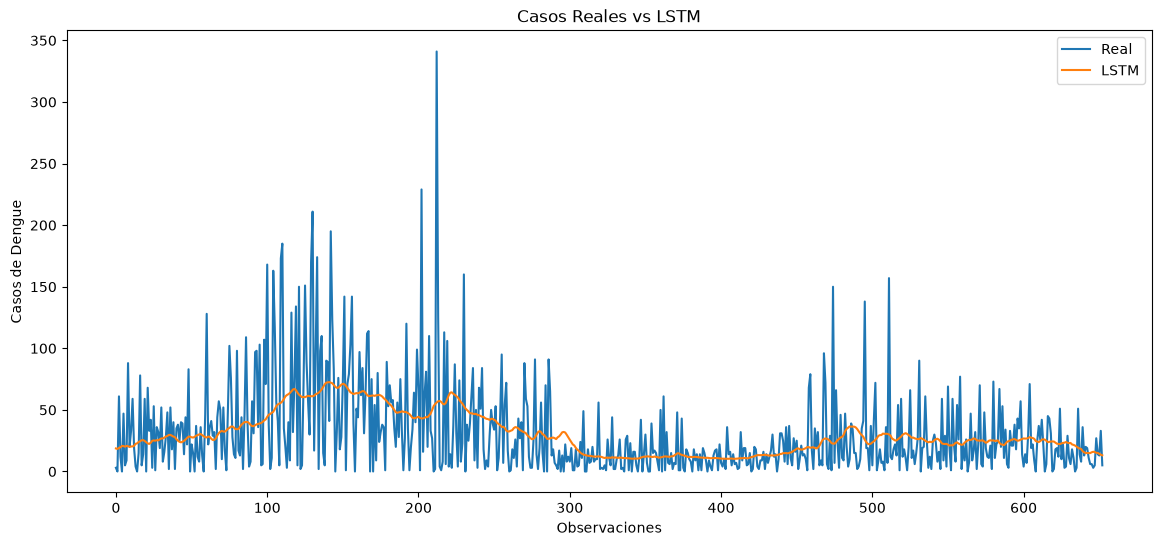

In [96]:
plt.figure(figsize=(14,6))

plt.plot(
    y_test_real,
    label="Real"
)

plt.plot(
    pred_lstm_real,
    label="LSTM"
)

plt.legend()

plt.title(
    "Casos Reales vs LSTM"
)

plt.xlabel(
    "Observaciones"
)

plt.ylabel(
    "Casos de Dengue"
)

plt.show()

## 8.4 Comparación

In [101]:
comparacion = pd.DataFrame({

    "Modelo": [
        "Baseline",
        "RNN",
        "LSTM"
    ],

    "MAE": [
        26.15,
        23.31,
        22.97
    ],

    "RMSE": [
        41.15,
        34.56,
        34.08
    ]
})

comparacion

,Modelo,MAE,RMSE
0,Baseline,26.15,41.15
1,RNN,23.31,34.56
2,LSTM,22.97,34.08


Observamos que el modelo que dio mejor resultados fue el LSTM con un total de 22.97 en MAE y 34.08 en RSME, como observamos hay semanas que se registraron mas de 340 casos lo cual nos dice que el modelo solo se equivoca en un aproximado del 10% en esas semanas críticas

# 9. Carga del Modelo

In [102]:
model_lstm.save(
    "../models/modelo_lstm_dengue.keras"
)
